# Chicago taxi trips, 11–17 September 2023

Descriptive summary of one week of **reported** taxi trips (the City notes not every trip is reported, so all figures are reported trips, not total market volume).

## Summary

_(summary placeholder)_

## 1. Setup and data loading

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 160

# Chart style: one hue for magnitude, blue/orange for a two-way comparison (validated reference palette).
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#8a8a86'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 10, 'font.size': 10,
})
thousands = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')
dollars   = mtick.FuncFormatter(lambda x, _: f'${x:,.0f}')

raw = pd.read_csv('trips.csv', parse_dates=['trip_start_timestamp', 'trip_end_timestamp'])
print(raw.shape)
print('Start range:', raw.trip_start_timestamp.min(), '->', raw.trip_start_timestamp.max())
print('Duplicate trip_id:', raw.trip_id.duplicated().sum(), '| fully duplicated rows:', raw.duplicated().sum())

(135768, 23)
Start range: 2023-09-11 00:00:00 -> 2023-09-17 23:45:00
Duplicate trip_id: 0 | fully duplicated rows: 0


## 2. Data checks and cleaning

First the checks, then the decisions. Every rule below is applied once, to the whole dataset, and **the same cleaned table (`df`) feeds every question**, so counts and shares are consistent across sections.

In [2]:
money = ['fare', 'tips', 'tolls', 'extras', 'trip_total']
num = ['trip_seconds', 'trip_miles'] + money
miss = raw.isna().sum()
print('Missing values (columns used in this analysis):')
print(miss[['trip_end_timestamp','trip_seconds','pickup_community_area','dropoff_community_area'] + money + ['payment_type','company','taxi_id']].to_frame('n_missing').assign(pct=lambda d: d.n_missing/len(raw)*100))
print()
print(raw[num].describe(percentiles=[.01, .5, .99, .999]).T)

Missing values (columns used in this analysis):
                        n_missing   pct
trip_end_timestamp              1  0.00
trip_seconds                   33  0.02
pickup_community_area        3815  2.81
dropoff_community_area      13794 10.16
fare                          324  0.24
tips                          324  0.24
tolls                         324  0.24
extras                        324  0.24
trip_total                    324  0.24
payment_type                    0  0.00
company                         0  0.00
taxi_id                         0  0.00

                  count     mean      std  min   1%      50%      99%     99.9%       max
trip_seconds 135,735.00 1,346.54 1,762.25 0.00 0.00 1,020.00 4,872.98 12,416.09 86,160.00
trip_miles   135,768.00     6.94     7.85 0.00 0.00     3.24    27.14     44.08    792.90
fare         135,444.00    23.87    19.60 0.00 3.25    17.75    75.50    150.00    911.00
tips         135,444.00     3.38     4.67 0.00 0.00     2.00    17.10  

In [3]:
# Where are the missing money fields? And what do zero / extreme values look like?
m = raw[raw.fare.isna()]
print('Rows with all five money fields missing:', len(m), '| all five missing together:', raw[money].isna().all(axis=1).sum())
print(m.payment_type.value_counts().to_string()); print()

print('trip_total == 0:', (raw.trip_total == 0).sum(), '| fare == 0:', (raw.fare == 0).sum())
print('trip_total > $500:', (raw.trip_total > 500).sum(), '| tolls > $100:', (raw.tolls > 100).sum(), '| extras > $100:', (raw.extras > 100).sum())
print('Zero miles AND zero seconds:', ((raw.trip_miles == 0) & (raw.trip_seconds.fillna(0) == 0)).sum(),
      '| zero miles (any duration):', (raw.trip_miles == 0).sum(), '| miles > 100:', (raw.trip_miles > 100).sum(),
      '| seconds > 4h:', (raw.trip_seconds > 4*3600).sum())
print()
print('Most extreme rows by trip_total:')
print(raw.nlargest(6, 'trip_total')[['trip_seconds','trip_miles','fare','tips','tolls','extras','trip_total','payment_type']])

Rows with all five money fields missing: 324 | all five missing together: 324
payment_type
Cash           323
Credit Card      1

trip_total == 0: 134 | fare == 0: 135
trip_total > $500: 8 | tolls > $100: 3 | extras > $100: 15
Zero miles AND zero seconds: 2649 | zero miles (any duration): 13993 | miles > 100: 11 | seconds > 4h: 121

Most extreme rows by trip_total:
        trip_seconds  trip_miles   fare  tips    tolls   extras  trip_total payment_type
124235      1,080.00        0.10  11.25  0.00 4,444.44 4,445.44    8,901.13         Cash
25636           0.00        0.00   3.25  0.00 4,444.44 4,444.44    8,892.13         Cash
35524         420.00        1.30   6.75  0.00 4,111.10     0.44    4,118.29         Cash
127990           NaN       37.45 911.00  0.00     0.00     0.00      911.00         Cash
31648           3.00        0.00 900.00  0.00     0.00     0.00      900.00         Cash
99632          60.00        0.00 758.00  0.00     0.00     0.00      758.00    No Charge


In [4]:
# Does trip_total equal fare + tips + tolls + extras?
gap = (raw.trip_total - raw[['fare','tips','tolls','extras']].sum(axis=1, skipna=False)).round(2)
print('Rows compared:', gap.notna().sum())
print(gap.value_counts().sort_index().rename('rows').to_frame().T.to_string()); print()
print('Rows where trip_total < sum of parts:', (gap < -0.005).sum(), '| largest gap:', gap.max())
print('Share of rows with trip_total > sum of parts, by payment type:')
print(raw.assign(over=gap > 0).groupby('payment_type').over.mean().mul(100).round(1).to_frame('% rows with gap'))
print()
print('gap of $2.50 / $3.00 rows, top pickup areas:', raw.loc[gap.isin([2.5, 3.0]), 'pickup_community_area'].value_counts().head(4).to_dict())

Rows compared: 135444
       0.00   0.50  1.00  1.50  1.95  2.00  2.50  3.00
rows  87247  46522   109     4     5     2   751   804

Rows where trip_total < sum of parts: 0 | largest gap: 3.0
Share of rows with trip_total > sum of parts, by payment type:
              % rows with gap
payment_type                 
Cash                     1.70
Credit Card             71.90
Dispute                  0.00
Mobile                  22.40
No Charge                0.00
Prcard                   0.10
Unknown                  0.00

gap of $2.50 / $3.00 rows, top pickup areas: {8.0: 859, 32.0: 446, 28.0: 122, 6.0: 45}


**Reading the checks**

- `trip_total` is **never lower** than the sum of its parts. In 48,197 rows (35.6%) it is higher, always by at most $3.00. The gap is $0.50 in 46,522 rows and is almost entirely on Credit Card and Mobile trips, so it looks like a card/processing charge that is not itemised in `fare`, `tips`, `tolls` or `extras`. The $2.50 and $3.00 gaps (1,555 rows) cluster in a handful of central pickup areas (8, 32, 28, 6) and may be a location surcharge; I have not confirmed this. 
- **Assumption:** `trip_total` is what the rider was billed, so I use it as revenue as reported and **do not** rebuild it from its parts. Rows with a small gap are kept; no gap is large enough to suggest corruption.
- The 324 rows with missing money fields are 99.7% Cash, with all five fields missing together, so revenue and tip cannot be recovered.
- Distance and duration have extreme values (e.g. 793 miles in 51 minutes, 23-hour trips) and 2,649 trips with zero miles and zero seconds (median fare $3.25, i.e. roughly a flag-drop fare). **None of the four questions uses miles or duration**, so those fields are reported here but not cleaned, and nothing is excluded for them.

In [5]:
# Exclusion rules, applied in order; each row is counted under the first rule it meets, so the counts add up.
rules = [
    ('R1  Missing fare/tips/tolls/extras/trip_total',   raw.trip_total.isna()),
    ('R2  trip_total = 0 (no revenue; fare is also 0)',   raw.trip_total.fillna(1) <= 0),
    ('R3  Extreme charge: trip_total > $500 or tolls/extras > $100',
        (raw.trip_total > 500) | (raw.tolls > 100) | (raw.extras > 100)),
]
remaining = pd.Series(True, index=raw.index)
log = []
for name, flag in rules:
    hit = flag & remaining
    log.append((name, int(hit.sum()), raw.loc[hit, 'trip_total'].sum()))
    remaining &= ~flag
log = pd.DataFrame(log, columns=['rule', 'rows_excluded', 'trip_total_removed($)'])
log.loc[len(log)] = ['Total excluded', log.rows_excluded.sum(), log['trip_total_removed($)'].sum()]
display(log)

df = raw[remaining].copy()
print(f'Rows kept: {len(df):,} of {len(raw):,} ({len(df)/len(raw):.2%})')

,rule,rows_excluded,trip_total_removed($)
0,R1 Missing fare/tips/tolls/extras/trip_total,324,0.00
1,R2 trip_total = 0 (no revenue; fare is also 0),134,0.00
2,R3 Extreme charge: trip_total > $500 or tolls...,21,"27,785.42"
3,Total excluded,479,"27,785.42"


Rows kept: 135,289 of 135,768 (99.65%)


**Cleaning decisions (all applied to every question below)**

| # | Decision | Rows affected |
|---|---|---|
| R1 | Drop trips with no money fields: no fare, tip or total to analyse. | 324 |
| R2 | Drop trips whose `trip_total` is $0 (fare also $0): no revenue, likely voided or test records. | 134 |
| R3 | Drop clearly erroneous charges: `trip_total` > $500 or tolls/extras > $100 (includes tolls/extras of $4,444.44 on a short trip and an $8,901 total). | 21 |
| | **Total excluded** | **479 of 135,768 (0.35%)** |
| – | Keep the $0.50–$3.00 gap between `trip_total` and its parts (see above). | 48,197 kept |
| – | Keep trips with zero miles/seconds and long durations: miles and duration are not used. | not excluded |
| – | Keep rows with no pickup community area but report their share explicitly (Q2). | kept |
| – | Treat `Unknown`, `No Charge` and `Dispute` as payment types in their own right (not dropped). | kept |
| – | Merge two company names that differ only in punctuation or a legal suffix (below). | see below |

I did **not** drop a further 119 trips (after R1–R3) with a fare over $100 but 0 miles, because a fare alone is not proof of error. A sensitivity check below shows they are 0.09% of trips and 0.60% of revenue, so they cannot change any conclusion.

In [6]:
# Company names: same company spelled two ways. Merge only the unambiguous cases.
variants = {'Taxicab Insurance Agency, LLC': 'Taxicab Insurance Agency Llc',
            'Choice Taxi Association Inc':   'Choice Taxi Association'}
print('Rows renamed:', df.company.isin(variants).sum(), '|', df.company[df.company.isin(variants)].value_counts().to_dict())
df['company'] = df.company.replace(variants)
print('Distinct companies:', raw.company.nunique(), '->', df.company.nunique())

# Do taxi_ids appear under more than one company?
print('taxi_ids under >1 company:', (df.groupby('taxi_id').company.nunique() > 1).sum(), 'of', df.taxi_id.nunique())

# Sensitivity: effect of the 155 'fare > $100 and 0 miles' trips that were kept
sus = (df.fare > 100) & (df.trip_miles == 0)
print(f'Kept trips with fare>$100 and 0 miles: {sus.sum()} = {sus.mean():.2%} of trips, {df.loc[sus,"trip_total"].sum()/df.trip_total.sum():.2%} of revenue')

# Time fields: derive day and hour from the (15-minute rounded) start timestamp
df['date'] = df.trip_start_timestamp.dt.normalize()
df['dow']  = df.trip_start_timestamp.dt.day_of_week          # Monday = 0
df['hour'] = df.trip_start_timestamp.dt.hour
df['is_weekend'] = df.dow >= 5

Rows renamed: 3424 | {'Taxicab Insurance Agency, LLC': 2361, 'Choice Taxi Association Inc': 1063}
Distinct companies: 32 -> 30


taxi_ids under >1 company: 3 of 2656
Kept trips with fare>$100 and 0 miles: 119 = 0.09% of trips, 0.60% of revenue


Notes on time: start timestamps are rounded to the nearest 15 minutes, so a trip beginning at 08:53 is stamped 09:00 and lands in the 09:00 hour. Hourly counts are therefore accurate to roughly ±7 minutes at the hour boundaries. All times are as given (local Chicago time is assumed; `dataset.md` does not state a time zone).

## 3. Q1 — When is demand highest?

,trips,share_pct
Mon,22100,16.34
Tue,21964,16.23
Wed,22619,16.72
Thu,22456,16.60
Fri,20163,14.90
Sat,12663,9.36
Sun,13324,9.85


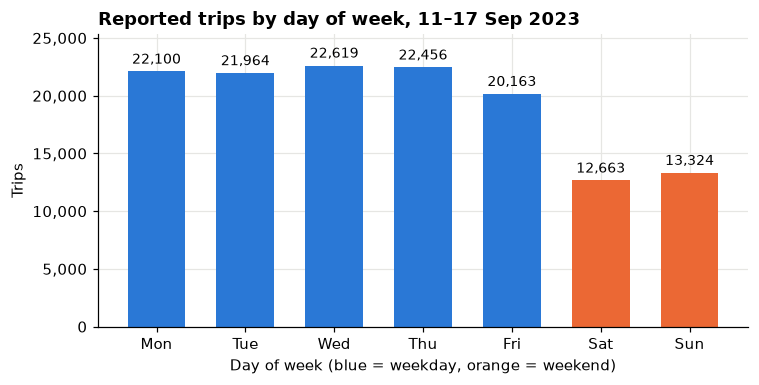

In [7]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
by_day = df.groupby('dow').size().reindex(range(7))
by_day.index = days
by_day_tbl = by_day.to_frame('trips').assign(share_pct=lambda d: d.trips / d.trips.sum() * 100)
display(by_day_tbl)

fig, ax = plt.subplots(figsize=(7, 3.6))
cols = [BLUE]*5 + [ORANGE]*2
bars = ax.bar(days, by_day.values, color=cols, width=0.65)
ax.bar_label(bars, labels=[f'{v:,}' for v in by_day.values], padding=3, fontsize=9)
ax.set_title('Reported trips by day of week, 11–17 Sep 2023')
ax.set_xlabel('Day of week (blue = weekday, orange = weekend)'); ax.set_ylabel('Trips')
ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0, by_day.max() * 1.12)
plt.tight_layout(); plt.show()

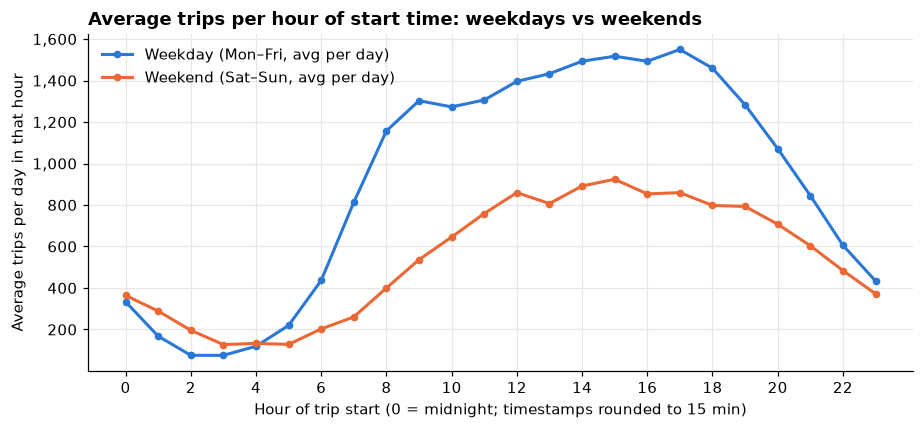

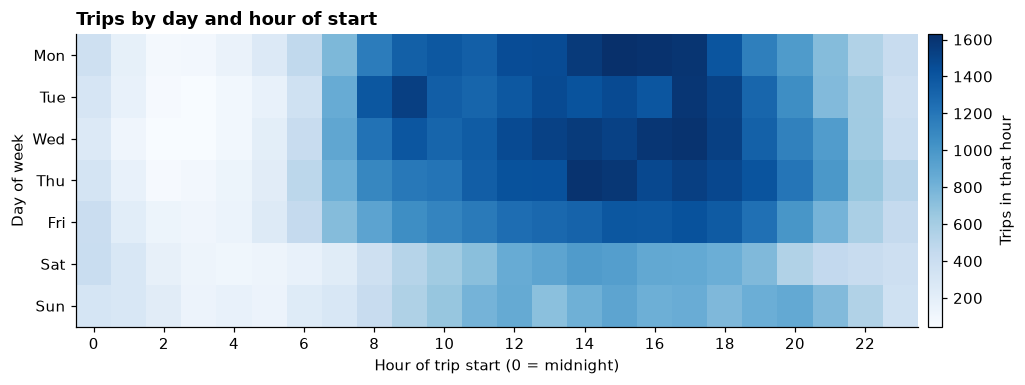

In [8]:
# Hour of day: average trips per hour on a weekday (Mon-Fri) vs a weekend day (Sat-Sun)
n_days = df.groupby('is_weekend').date.nunique()
hourly = (df.groupby(['is_weekend', 'hour']).size().unstack(0).reindex(range(24), fill_value=0)
            .rename(columns={False: 'Weekday', True: 'Weekend'}))
hourly_avg = hourly / n_days.rename({False: 'Weekday', True: 'Weekend'})
hourly_avg['Total trips (week)'] = hourly.sum(axis=1)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(hourly_avg.index, hourly_avg['Weekday'], color=BLUE, lw=2, marker='o', ms=4, label='Weekday (Mon–Fri, avg per day)')
ax.plot(hourly_avg.index, hourly_avg['Weekend'], color=ORANGE, lw=2, marker='o', ms=4, label='Weekend (Sat–Sun, avg per day)')
ax.set_title('Average trips per hour of start time: weekdays vs weekends')
ax.set_xlabel('Hour of trip start (0 = midnight; timestamps rounded to 15 min)'); ax.set_ylabel('Average trips per day in that hour')
ax.set_xticks(range(0, 24, 2)); ax.yaxis.set_major_formatter(thousands)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# Day x hour heatmap
grid = df.groupby(['dow', 'hour']).size().unstack().reindex(index=range(7), columns=range(24), fill_value=0)
grid.index = days
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(grid.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(7)); ax.set_yticklabels(days); ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.grid(False)
ax.set_title('Trips by day and hour of start'); ax.set_xlabel('Hour of trip start (0 = midnight)'); ax.set_ylabel('Day of week')
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label('Trips in that hour')
plt.tight_layout(); plt.show()

In [9]:
wk, we = hourly_avg['Weekday'], hourly_avg['Weekend']
tot_hr = hourly['Weekday'] + hourly['Weekend']
print('Busiest day:', by_day.idxmax(), f'({by_day.max():,})', '| quietest day:', by_day.idxmin(), f'({by_day.min():,})')
print(f'Mon–Thu average: {by_day[:4].mean():,.0f} | Fri: {by_day["Fri"]:,} | Sat–Sun average: {by_day[5:].mean():,.0f} ({by_day[5:].mean()/by_day[:4].mean()-1:+.0%} vs Mon–Thu)')
print('Peak hour, weekday:', wk.idxmax(), f'({wk.max():,.0f}/day) | weekend:', we.idxmax(), f'({we.max():,.0f}/day)')
print('Quietest hour, weekday:', wk.idxmin(), f'({wk.min():,.0f}/day) | weekend:', we.idxmin(), f'({we.min():,.0f}/day)')
print('Top 5 hours of the week overall:', tot_hr.nlargest(5).to_dict())
print('Busiest single day-hour cell:', grid.stack().idxmax(), grid.stack().max(), '| quietest:', grid.stack().idxmin(), grid.stack().min())
print('Share of trips starting 3–6pm weekday:', f'{hourly.loc[15:17,"Weekday"].sum()/hourly["Weekday"].sum():.1%}')
print('Weekday ratio evening (18-23h) vs weekend evening:', round(wk.loc[18:23].sum()/we.loc[18:23].sum(), 2))
display(hourly_avg.round(0).astype(int).T)

Busiest day: Wed (22,619) | quietest day: Sat (12,663)
Mon–Thu average: 22,285 | Fri: 20,163 | Sat–Sun average: 12,994 (-42% vs Mon–Thu)
Peak hour, weekday: 17 (1,550/day) | weekend: 15 (924/day)
Quietest hour, weekday: 3 (75/day) | weekend: 3 (127/day)
Top 5 hours of the week overall: {17: 9468, 15: 9433, 14: 9249, 16: 9172, 18: 8893}
Busiest single day-hour cell: ('Mon', 15) 1629 | quietest: ('Wed', 3) 45
Share of trips starting 3–6pm weekday: 20.9%
Weekday ratio evening (18-23h) vs weekend evening: 1.52


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
is_weekend,,,,,,,,,,,,,,,,,,,,,
Weekday,334,168,75,75,119,219,436,813,1157,1303,...,1493,1517,1493,1550,1459,1283,1072,845,606,434
Weekend,364,288,196,127,133,128,202,260,400,536,...,892,924,854,860,798,793,708,604,484,372
Total trips (week),2396,1415,769,630,862,1353,2587,4587,6586,7587,...,9249,9433,9172,9468,8893,8000,6773,5434,3998,2915


**Takeaway (Q1)**: PLACEHOLDER_Q1

## 4. Q2 — Where do trips start?

Geography uses pickup **community area** codes (1–77), as asked. Names are not added because outside data is out of scope.

In [10]:
pa = df.groupby('pickup_community_area').agg(trips=('trip_id', 'size'), total_revenue=('trip_total', 'sum'))
pa.index = pa.index.astype(int); pa.index.name = 'community_area'
pa['trip_share_pct'] = pa.trips / len(df) * 100
pa['revenue_share_pct'] = pa.total_revenue / df.trip_total.sum() * 100

top_trips = pa.nlargest(10, 'trips').assign(rank_trips=range(1, 11))
top_rev = pa.nlargest(10, 'total_revenue').assign(rank_revenue=range(1, 11))
print('Top 10 pickup community areas by trip count'); display(top_trips[['rank_trips','trips','trip_share_pct','total_revenue']])
print('Top 10 pickup community areas by total trip_total ($)'); display(top_rev[['rank_revenue','total_revenue','revenue_share_pct','trips']])
print('Areas in both lists:', len(set(top_trips.index) & set(top_rev.index)), '| in one only:', sorted(set(top_trips.index) ^ set(top_rev.index)))
print('Top 10 by trips cover', f'{top_trips.trips.sum()/len(df):.1%}', 'of all trips;', 'top 3 cover', f'{top_trips.trips.head(3).sum()/len(df):.1%}')

no_area = df.pickup_community_area.isna()
print(f'\nTrips with no pickup community area: {no_area.sum():,} = {no_area.mean():.2%} of {len(df):,} trips '
      f'(raw file before cleaning: {raw.pickup_community_area.isna().mean():.2%}); revenue share {df.loc[no_area,"trip_total"].sum()/df.trip_total.sum():.2%}')
print('  ...of which have no pickup latitude/longitude either:', f'{df.loc[no_area,"pickup_centroid_latitude"].isna().mean():.1%}',
      '| and no pickup census tract:', f'{df.loc[no_area,"pickup_census_tract"].isna().mean():.1%}')
print('  Their average trip_total: $%.2f vs $%.2f for trips with an area; average miles %.1f vs %.1f' % (
      df.loc[no_area,'trip_total'].mean(), df.loc[~no_area,'trip_total'].mean(), df.loc[no_area,'trip_miles'].mean(), df.loc[~no_area,'trip_miles'].mean()))

Top 10 pickup community areas by trip count


,rank_trips,trips,trip_share_pct,total_revenue
community_area,,,,
76,1,31557,23.33,"1,731,590.59"
8,2,28219,20.86,"518,444.97"
32,3,22068,16.31,"421,676.49"
28,4,11252,8.32,"185,577.30"
33,5,6676,4.93,"172,208.31"
56,6,5404,3.99,"252,724.43"
6,7,3926,2.90,"78,120.32"
7,8,2537,1.88,"48,932.15"
3,9,1916,1.42,"39,480.89"


Top 10 pickup community areas by total trip_total ($)


,rank_revenue,total_revenue,revenue_share_pct,trips
community_area,,,,
76,1,"1,731,590.59",42.74,31557
8,2,"518,444.97",12.80,28219
32,3,"421,676.49",10.41,22068
56,4,"252,724.43",6.24,5404
28,5,"185,577.30",4.58,11252
33,6,"172,208.31",4.25,6676
6,7,"78,120.32",1.93,3926
7,8,"48,932.15",1.21,2537
3,9,"39,480.89",0.97,1916


Areas in both lists: 10 | in one only: []
Top 10 by trips cover 85.1% of all trips; top 3 cover 60.5%

Trips with no pickup community area: 3,793 = 2.80% of 135,289 trips (raw file before cleaning: 2.81%); revenue share 3.43%
  ...of which have no pickup latitude/longitude either: 98.9% | and no pickup census tract: 97.7%
  Their average trip_total: $36.65 vs $29.75 for trips with an area; average miles 6.3 vs 7.0


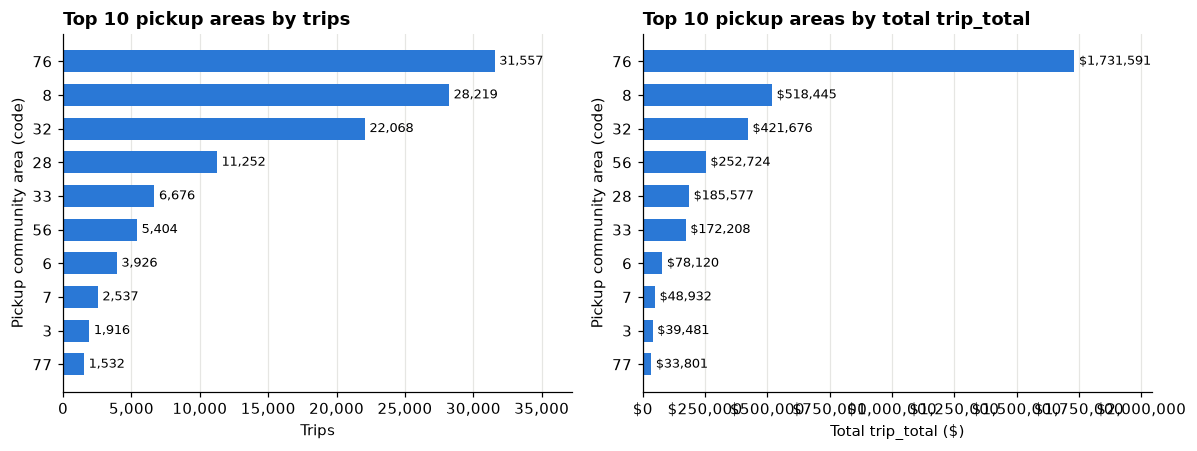

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, tbl, col, title, xlabel, fmt in [
    (axes[0], top_trips, 'trips', 'Top 10 pickup areas by trips', 'Trips', thousands),
    (axes[1], top_rev, 'total_revenue', 'Top 10 pickup areas by total trip_total', 'Total trip_total ($)', dollars)]:
    t = tbl.sort_values(col)
    b = ax.barh(t.index.astype(str), t[col], color=BLUE, height=0.65)
    ax.bar_label(b, labels=[f'{v:,.0f}' if col=='trips' else f'${v:,.0f}' for v in t[col]], padding=3, fontsize=8.5)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('Pickup community area (code)')
    ax.xaxis.set_major_formatter(fmt); ax.set_xlim(0, t[col].max() * 1.18); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Takeaway (Q2)**: PLACEHOLDER_Q2

## 5. Q3 — How do riders pay and tip?

Definitions: *revenue* = sum of `trip_total`; *average fare* = mean `fare`; *tip % of fare* = sum of `tips` ÷ sum of `fare` (an aggregate ratio, so zero-fare and tiny-fare trips cannot blow up a per-trip percentage). *% trips with a tip* = share of trips with `tips` > 0. Cash tips are generally not recorded, so tip figures for non-card types are **not** comparable with cards.

In [12]:
pay = df.groupby('payment_type').agg(trips=('trip_id', 'size'), total_revenue=('trip_total', 'sum'),
                                     avg_fare=('fare', 'mean'), fare_sum=('fare', 'sum'), tips_sum=('tips', 'sum'),
                                     pct_trips_with_tip=('tips', lambda s: (s > 0).mean() * 100))
pay['trip_share_pct'] = pay.trips / pay.trips.sum() * 100
pay['revenue_share_pct'] = pay.total_revenue / pay.total_revenue.sum() * 100
pay['tip_pct_of_fare'] = pay.tips_sum / pay.fare_sum * 100
pay = pay.sort_values('trips', ascending=False)
cols = ['trips', 'trip_share_pct', 'total_revenue', 'revenue_share_pct', 'avg_fare', 'tips_sum', 'tip_pct_of_fare', 'pct_trips_with_tip']
tot = pd.Series({'trips': pay.trips.sum(), 'trip_share_pct': 100.0, 'total_revenue': pay.total_revenue.sum(), 'revenue_share_pct': 100.0,
                 'avg_fare': df.fare.mean(), 'tips_sum': pay.tips_sum.sum(), 'tip_pct_of_fare': pay.tips_sum.sum()/pay.fare_sum.sum()*100,
                 'pct_trips_with_tip': (df.tips > 0).mean() * 100}, name='All trips')
display(pd.concat([pay[cols], tot.to_frame().T])
        .style.format({'trips': '{:,.0f}', 'total_revenue': '${:,.0f}', 'avg_fare': '${:.2f}', 'tips_sum': '${:,.0f}', 'trip_share_pct': '{:.1f}%',
                       'revenue_share_pct': '{:.1f}%', 'tip_pct_of_fare': '{:.1f}%', 'pct_trips_with_tip': '{:.1f}%'}))

# Like-for-like tipping: only the two card-based types where tips are recorded
card = df[df.payment_type.isin(['Credit Card', 'Mobile'])]
c = card.groupby('payment_type').apply(lambda g: pd.Series({'trips': len(g), 'tip_pct_of_fare': g.tips.sum()/g.fare.sum()*100,
        'median_tip_pct_of_fare (tipped trips, fare>0)': (g.tips/g.fare)[(g.tips > 0) & (g.fare > 0)].median()*100,
        '% trips tipped': (g.tips > 0).mean()*100}), include_groups=False)
print('Tipping on Credit Card vs Mobile only (tips recorded for both):'); display(c.round(1))

,trips,trip_share_pct,total_revenue,revenue_share_pct,avg_fare,tips_sum,tip_pct_of_fare,pct_trips_with_tip
Credit Card,"60,276",44.6%,"$2,420,060",59.7%,$29.04,"$386,801",22.1%,93.6%
Cash,"39,592",29.3%,"$791,447",19.5%,$18.33,$949,0.1%,0.4%
Mobile,"18,594",13.7%,"$413,943",10.2%,$17.81,"$67,718",20.5%,92.7%
Prcard,"11,961",8.8%,"$307,514",7.6%,$25.43,"$2,266",0.7%,5.2%
Unknown,"4,783",3.5%,"$115,614",2.9%,$24.04,$18,0.0%,0.1%
No Charge,52,0.0%,"$2,233",0.1%,$36.28,$34,1.8%,7.7%
Dispute,31,0.0%,$752,0.0%,$21.31,$0,0.0%,0.0%
All trips,"135,289",100.0%,"$4,051,564",100.0%,$23.87,"$457,787",14.2%,55.0%


Tipping on Credit Card vs Mobile only (tips recorded for both):


,trips,tip_pct_of_fare,"median_tip_pct_of_fare (tipped trips, fare>0)",% trips tipped
payment_type,,,,
Credit Card,"60,276.00",22.10,23.00,93.60
Mobile,"18,594.00",20.50,22.80,92.70


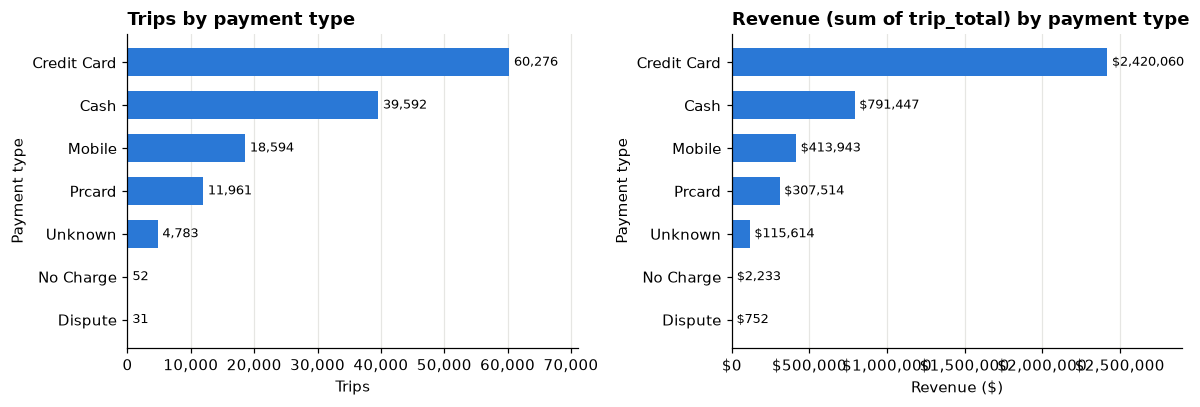

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
order = pay.sort_values('trips').index
b = axes[0].barh(order, pay.loc[order, 'trips'], color=BLUE, height=0.65)
axes[0].bar_label(b, labels=[f'{v:,.0f}' for v in pay.loc[order, 'trips']], padding=3, fontsize=8.5)
axes[0].set_title('Trips by payment type'); axes[0].set_xlabel('Trips'); axes[0].set_ylabel('Payment type')
axes[0].xaxis.set_major_formatter(thousands); axes[0].set_xlim(0, pay.trips.max()*1.18)
b = axes[1].barh(order, pay.loc[order, 'total_revenue'], color=BLUE, height=0.65)
axes[1].bar_label(b, labels=[f'${v:,.0f}' for v in pay.loc[order, 'total_revenue']], padding=3, fontsize=8.5)
axes[1].set_title('Revenue (sum of trip_total) by payment type'); axes[1].set_xlabel('Revenue ($)'); axes[1].set_ylabel('Payment type')
axes[1].xaxis.set_major_formatter(dollars); axes[1].set_xlim(0, pay.total_revenue.max()*1.2)
for a in axes: a.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Takeaway (Q3)**: PLACEHOLDER_Q3

## 6. Q4 — Which companies carry the trips?

`taxi_id` counts are distinct taxis seen in this week's reported trips for that company. Two company names that differed only by punctuation/legal suffix were merged (section 2); 3 of 2,656 `taxi_id`s appear under two companies, so company taxi counts can overlap very slightly.

,trips,total_revenue,distinct_taxis,share_of_all_trips_pct,revenue_per_trip,trips_per_taxi
company,,,,,,
Flash Cab,"25,895","$684,964",401,19.1%,$26.45,64.6
Taxi Affiliation Services,"25,670","$729,121",457,19.0%,$28.40,56.2
Taxicab Insurance Agency Llc,"16,164","$525,667",356,11.9%,$32.52,45.4
Sun Taxi,"15,074","$483,792",299,11.1%,$32.09,50.4
City Service,"13,653","$422,127",265,10.1%,$30.92,51.5
Chicago Independents,"7,965","$262,606",189,5.9%,$32.97,42.1
5 Star Taxi,"6,119","$210,351",140,4.5%,$34.38,43.7
Medallion Leasin,"4,996","$153,736",98,3.7%,$30.77,51.0
Globe Taxi,"4,753","$141,225",104,3.5%,$29.71,45.7


Top 10 companies: 92.2% of trips, 92.1% of revenue, 2,417 taxis of 2,656. Top 3: 50.1% of trips.
Companies in total: 30 | Next company after the top 10: Choice Taxi Association (3,071 trips)


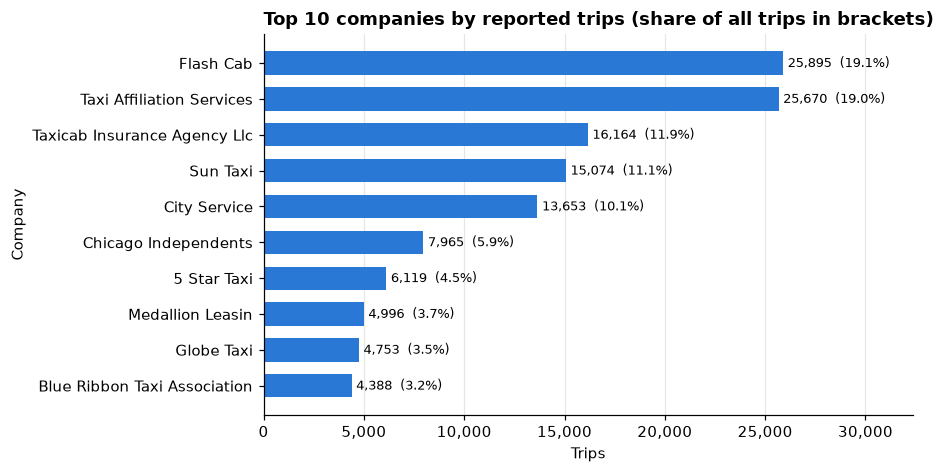

In [14]:
co = df.groupby('company').agg(trips=('trip_id', 'size'), total_revenue=('trip_total', 'sum'), distinct_taxis=('taxi_id', 'nunique'))
co['share_of_all_trips_pct'] = co.trips / len(df) * 100
co['revenue_per_trip'] = co.total_revenue / co.trips
co['trips_per_taxi'] = co.trips / co.distinct_taxis
top_co = co.nlargest(10, 'trips')
top_co.index.name = 'company'
display(top_co.style.format({'trips': '{:,.0f}', 'total_revenue': '${:,.0f}', 'distinct_taxis': '{:,.0f}', 'share_of_all_trips_pct': '{:.1f}%',
                             'revenue_per_trip': '${:.2f}', 'trips_per_taxi': '{:.1f}'}))
print(f'Top 10 companies: {top_co.trips.sum()/len(df):.1%} of trips, {top_co.total_revenue.sum()/df.trip_total.sum():.1%} of revenue, '
      f'{top_co.distinct_taxis.sum():,} taxis of {df.taxi_id.nunique():,}. Top 3: {top_co.trips.head(3).sum()/len(df):.1%} of trips.')
print('Companies in total:', len(co), '| Next company after the top 10:', co.nlargest(11, 'trips').index[-1], f'({co.trips.nlargest(11).iloc[-1]:,} trips)')

fig, ax = plt.subplots(figsize=(8.5, 4.4))
t = top_co.sort_values('trips')
b = ax.barh(t.index, t.trips, color=BLUE, height=0.65)
ax.bar_label(b, labels=[f'{n:,.0f}  ({s:.1f}%)' for n, s in zip(t.trips, t.share_of_all_trips_pct)], padding=3, fontsize=8.5)
ax.set_title('Top 10 companies by reported trips (share of all trips in brackets)')
ax.set_xlabel('Trips'); ax.set_ylabel('Company'); ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, t.trips.max()*1.25); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Takeaway (Q4)**: PLACEHOLDER_Q4

## 7. Assumptions, limitations and follow-up

- All figures are **reported** trips, not the whole market. Companies may differ in how completely they report, so company shares are shares of reported trips.
- Revenue is the sum of the reported `trip_total` (a gross billed amount, including tips, tolls and extras); it is not company earnings.
- One week, so no comparison with other weeks; Monday–Sunday patterns may not generalise to other times of year.
- Time zone is assumed to be local Chicago time. Hourly counts are blurred by the 15-minute timestamp rounding.
- Tips: cash tips are not recorded, and `Prcard`/`Unknown`/others show almost no tips, so tip rates are only meaningful for Credit Card and Mobile.
- **Possible follow-up:** PLACEHOLDER_FOLLOWUP